# Part C: Accessibility Analysis

This notebook compares accessibility to essential services by private car and public transport across Burnie SA1s. Accessibility is evaluated using 15, 30 and 45-minute travel-time thresholds for four service categories: schools, health services, pharmacies and supermarkets.

In [1]:
# Import libraries

from pathlib import Path

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

print("Accessibility analysis environment is working.")

Accessibility analysis environment is working.


In [2]:
# Set project paths

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

analysis_ready = (
    project_root / "data" / "processed" / "analysis_ready"
)

print("Analysis-ready folder exists:", analysis_ready.exists())

Analysis-ready folder exists: True


In [3]:
# Load car and public-transport travel-time matrices

car_matrix = pd.read_csv(
    analysis_ready / "car_travel_times_20261020_0900.csv"
)

pt_matrix = pd.read_csv(
    analysis_ready / "pt_travel_times_20261020_0900.csv"
)

print("Car OD pairs:", len(car_matrix))
print("PT OD pairs:", len(pt_matrix))

print("\nCar missing travel times:",
      car_matrix["travel_time"].isna().sum())

print("PT missing travel times:",
      pt_matrix["travel_time"].isna().sum())

Car OD pairs: 1456
PT OD pairs: 1456

Car missing travel times: 0
PT missing travel times: 250


## C1. Accessibility by Travel-Time Threshold

Accessibility is calculated for 15, 30 and 45-minute travel-time thresholds. For each SA1, the proportion of destinations reachable within each threshold is calculated separately for schools, health services, pharmacies and supermarkets. The four category proportions are then given equal weight to produce an overall accessibility score between 0 and 1.

In [4]:
# Check the number of destinations in each service category

service_totals = (
    car_matrix
    .groupby("service_type")["to_id"]
    .nunique()
)

print("Destinations by service category:")
print(service_totals)

Destinations by service category:
service_type
Health          7
Pharmacy        5
School         10
Supermarket     4
Name: to_id, dtype: int64


In [6]:
# Calculate accessibility scores for 15, 30 and 45-minute thresholds

thresholds = [15, 30, 45]

def calculate_accessibility(matrix, mode_name):

    results = []

    for threshold in thresholds:

        temp = matrix.copy()

        # A destination is reachable when travel time is within the threshold.
        # Missing PT travel times are therefore treated as unreachable.
        temp["reachable"] = (
            temp["travel_time"] <= threshold
        )

        # Count reachable destinations in each service category
        category_access = (
            temp
            .groupby(["from_id", "service_type"])["reachable"]
            .sum()
            .reset_index(name="reachable_count")
        )

        # Add the total number of destinations in each category
        category_access["total_destinations"] = (
            category_access["service_type"]
            .map(service_totals)
        )

        # Convert counts to proportions
        category_access["access_proportion"] = (
            category_access["reachable_count"]
            / category_access["total_destinations"]
        )

        # Put the four service categories into separate columns
        accessibility_wide = (
            category_access
            .pivot(
                index="from_id",
                columns="service_type",
                values="access_proportion"
            )
            .fillna(0)
        )

        # Equal-weight the four service categories
        accessibility_wide["overall_accessibility"] = (
            accessibility_wide[
                ["School", "Health", "Pharmacy", "Supermarket"]
            ]
            .mean(axis=1)
        )

        accessibility_wide["threshold_min"] = threshold
        accessibility_wide["mode"] = mode_name

        results.append(
            accessibility_wide.reset_index()
        )

    return pd.concat(
        results,
        ignore_index=True
    )

In [7]:
# Calculate car and public-transport accessibility

car_access = calculate_accessibility(
    car_matrix,
    "Car"
)

pt_access = calculate_accessibility(
    pt_matrix,
    "Public transport"
)

print("Car accessibility rows:", len(car_access))
print("PT accessibility rows:", len(pt_access))

display(car_access.head())

Car accessibility rows: 168
PT accessibility rows: 168


service_type,from_id,Health,Pharmacy,School,Supermarket,overall_accessibility,threshold_min,mode
0,60401107501,1.0,1.0,1.0,1.0,1.0,15,Car
1,60401107502,1.0,1.0,1.0,1.0,1.0,15,Car
2,60401107503,1.0,1.0,1.0,1.0,1.0,15,Car
3,60401107504,1.0,1.0,1.0,1.0,1.0,15,Car
4,60401107505,1.0,1.0,1.0,1.0,1.0,15,Car


## C2. Compare Car and Public-Transport Accessibility

Overall accessibility is compared between private car and public transport at each travel-time threshold. Higher values indicate that a greater proportion of the four essential-service categories can be reached within the specified travel time.

In [8]:
# Summarise average accessibility by mode and threshold

access_summary = pd.concat(
    [car_access, pt_access],
    ignore_index=True
)

summary_by_threshold = (
    access_summary
    .groupby(["mode", "threshold_min"])["overall_accessibility"]
    .agg(["mean", "median", "min", "max"])
    .reset_index()
)

display(summary_by_threshold)

,mode,threshold_min,mean,median,min,max
0,Car,15,0.941964,1.000000,0.0,1.000000
1,Car,30,0.979241,1.000000,0.0,1.000000
2,Car,45,1.000000,1.000000,1.0,1.000000
3,Public transport,15,0.058897,0.025000,0.0,0.296429
4,Public transport,30,0.255931,0.223214,0.0,0.739286
5,Public transport,45,0.561990,0.692857,0.0,0.950000


In [9]:
# Combine car and public-transport accessibility scores

car_overall = car_access[
    ["from_id", "threshold_min", "overall_accessibility"]
].rename(
    columns={
        "overall_accessibility": "car_access"
    }
)

pt_overall = pt_access[
    ["from_id", "threshold_min", "overall_accessibility"]
].rename(
    columns={
        "overall_accessibility": "pt_access"
    }
)

access_comparison = car_overall.merge(
    pt_overall,
    on=["from_id", "threshold_min"],
    how="left"
)

# Difference between car and PT accessibility
access_comparison["access_gap"] = (
    access_comparison["car_access"]
    - access_comparison["pt_access"]
)

display(access_comparison.head(10))

service_type,from_id,threshold_min,car_access,pt_access,access_gap
0,60401107501,15,1.0,0.208929,0.791071
1,60401107502,15,1.0,0.098214,0.901786
2,60401107503,15,1.0,0.098214,0.901786
3,60401107504,15,1.0,0.183929,0.816071
4,60401107505,15,1.0,0.096429,0.903571
5,60401107506,15,1.0,0.071429,0.928571
6,60401107507,15,1.0,0.071429,0.928571
7,60401107508,15,1.0,0.219643,0.780357
8,60401107601,15,0.0,0.000000,0.000000
9,60401107604,15,0.0,0.000000,0.000000


In [10]:
# Summarise the car advantage at each threshold

gap_summary = (
    access_comparison
    .groupby("threshold_min")["access_gap"]
    .agg(["mean", "median", "min", "max"])
    .reset_index()
)

display(gap_summary)

,threshold_min,mean,median,min,max
0,15,0.883068,0.957143,0.00,1.0
1,30,0.723310,0.776786,0.00,1.0
2,45,0.438010,0.307143,0.05,1.0


## C3. Car Dependency Index

The Car Dependency Index (CDI) measures the relative accessibility advantage of private car travel compared with public transport. CDI is calculated separately for the 15, 30 and 45-minute accessibility thresholds.

\[
CDI = \frac{A_{car} - A_{PT}}{A_{car} + A_{PT}}
\]

Positive values indicate greater accessibility by car, values near zero indicate similar accessibility between modes, and negative values indicate greater accessibility by public transport. Where both modes have zero accessibility, CDI is left undefined because equal lack of access is not equivalent to equal accessibility.

In [11]:
# Calculate the Car Dependency Index

denominator = (
    access_comparison["car_access"]
    + access_comparison["pt_access"]
)

access_comparison["CDI"] = np.where(
    denominator > 0,
    (
        access_comparison["car_access"]
        - access_comparison["pt_access"]
    ) / denominator,
    np.nan
)

print("Undefined CDI values:",
      access_comparison["CDI"].isna().sum())

display(access_comparison.head(15))

Undefined CDI values: 3


service_type,from_id,threshold_min,car_access,pt_access,access_gap,CDI
0,60401107501,15,1.000000,0.208929,0.791071,0.654357
1,60401107502,15,1.000000,0.098214,0.901786,0.821138
2,60401107503,15,1.000000,0.098214,0.901786,0.821138
3,60401107504,15,1.000000,0.183929,0.816071,0.689291
4,60401107505,15,1.000000,0.096429,0.903571,0.824104
5,60401107506,15,1.000000,0.071429,0.928571,0.866667
6,60401107507,15,1.000000,0.071429,0.928571,0.866667
7,60401107508,15,1.000000,0.219643,0.780357,0.639824
8,60401107601,15,0.000000,0.000000,0.000000,NaN
9,60401107604,15,0.000000,0.000000,0.000000,NaN


In [12]:
# Summarise CDI by travel-time threshold

cdi_summary = (
    access_comparison
    .groupby("threshold_min")["CDI"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)

display(cdi_summary)

,threshold_min,count,mean,median,min,max
0,15,54,0.894271,0.951220,0.542700,1.0
1,30,55,0.629863,0.635036,0.149897,1.0
2,45,56,0.344328,0.181435,0.025641,1.0


In [13]:
# Save accessibility and CDI results

access_comparison.to_csv(
    analysis_ready / "accessibility_cdi_by_threshold.csv",
    index=False
)

car_access.to_csv(
    analysis_ready / "car_accessibility_by_threshold.csv",
    index=False
)

pt_access.to_csv(
    analysis_ready / "pt_accessibility_by_threshold.csv",
    index=False
)

print("Accessibility results saved.")

Accessibility results saved.


## C4. Spatial Pattern of Car Dependency

The Car Dependency Index is mapped at the 15, 30 and 45-minute thresholds. The same CDI scale from 0 to 1 is used for each map so that spatial patterns can be compared directly across travel-time thresholds. SA1s where both modes provide zero accessibility are shown as no data.

In [14]:
# Load the Burnie SA1 spatial layer

burnie_sa1 = gpd.read_file(
    analysis_ready / "burnie_sa1_seifa.gpkg"
)

burnie_sa1["SA1_CODE_2021"] = (
    burnie_sa1["SA1_CODE_2021"].astype(str)
)

print("Burnie SA1s:", len(burnie_sa1))

Burnie SA1s: 56


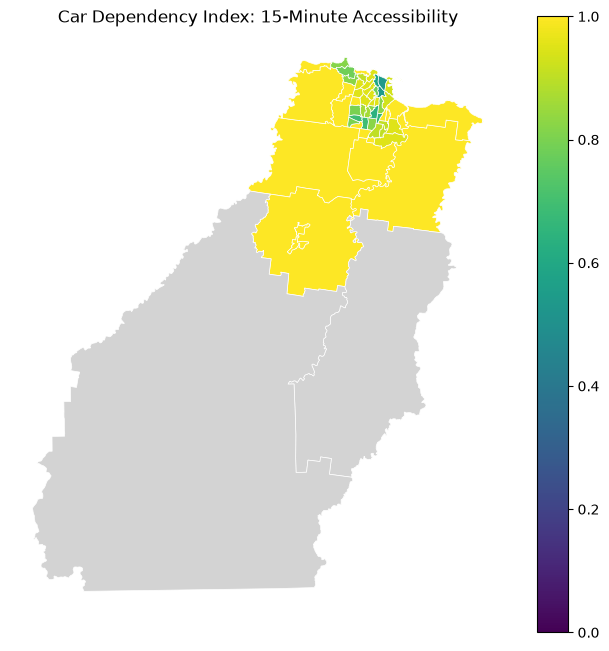

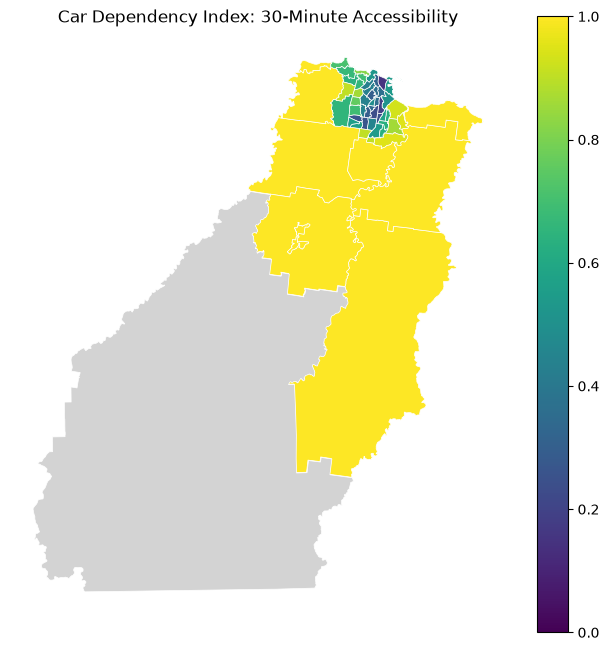

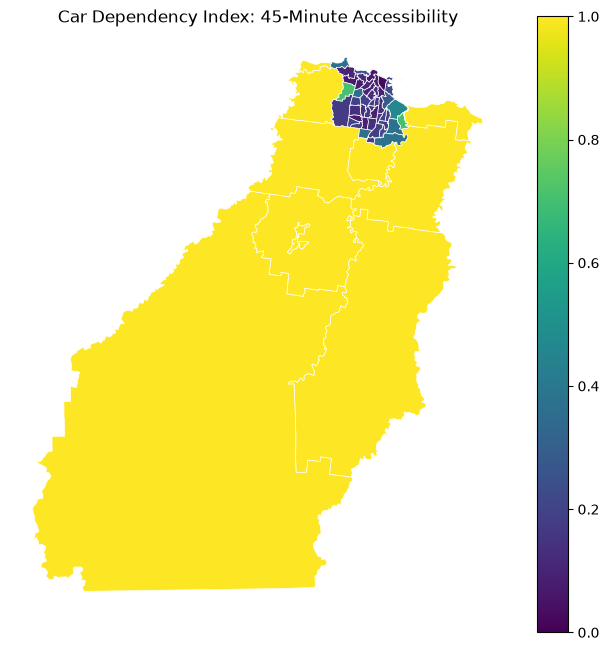

In [15]:
# Map CDI separately for each travel-time threshold

for threshold in [15, 30, 45]:

    cdi_threshold = access_comparison[
        access_comparison["threshold_min"] == threshold
    ][
        ["from_id", "CDI"]
    ].copy()

    cdi_threshold["from_id"] = (
        cdi_threshold["from_id"].astype(str)
    )

    cdi_map = burnie_sa1.merge(
        cdi_threshold,
        left_on="SA1_CODE_2021",
        right_on="from_id",
        how="left"
    )

    fig, ax = plt.subplots(figsize=(8, 8))

    cdi_map.plot(
        column="CDI",
        ax=ax,
        legend=True,
        vmin=0,
        vmax=1,
        edgecolor="white",
        linewidth=0.5,
        missing_kwds={
            "color": "lightgrey",
            "label": "No access by either mode"
        }
    )

    ax.set_title(
        f"Car Dependency Index: {threshold}-Minute Accessibility"
    )

    ax.set_axis_off()

    plt.show()

## C5. Primary Car Dependency Result

The 30-minute threshold is used as the primary accessibility scenario because it provides a middle-ground measure between short local access (15 minutes) and extended travel (45 minutes). The 15 and 45-minute scenarios are retained as sensitivity tests to assess how the spatial pattern changes with travel-time assumptions.

In [16]:
# Extract the primary 30-minute CDI result

cdi_30 = access_comparison[
    access_comparison["threshold_min"] == 30
].copy()

print("30-minute CDI records:", len(cdi_30))
print("Defined CDI values:", cdi_30["CDI"].notna().sum())
print("Undefined CDI values:", cdi_30["CDI"].isna().sum())

print("\n30-minute CDI summary:")
print(cdi_30["CDI"].describe())

30-minute CDI records: 56
Defined CDI values: 55
Undefined CDI values: 1

30-minute CDI summary:
count    55.000000
mean      0.629863
std       0.265401
min       0.149897
25%       0.432225
50%       0.635036
75%       0.904762
max       1.000000
Name: CDI, dtype: float64


In [17]:
# Save the primary 30-minute CDI results

cdi_30.to_csv(
    analysis_ready / "cdi_30min.csv",
    index=False
)

print("30-minute CDI saved.")

30-minute CDI saved.


# Part C2: Expanded Six-Category Accessibility Analysis

The accessibility analysis is repeated using six equally weighted categories: schools, health services, pharmacies, supermarkets, greenspace and leisure. This expanded analysis complements the original four-category essential-service assessment by incorporating access to local recreational opportunities.

In [18]:
# Load the expanded six-category travel-time matrices

car_6 = pd.read_csv(
    analysis_ready / "car_travel_times_6categories_20261020_0900.csv"
)

pt_6 = pd.read_csv(
    analysis_ready / "pt_travel_times_6categories_20261020_0900.csv"
)

print("Car OD pairs:", len(car_6))
print("PT OD pairs:", len(pt_6))

print("\nCar missing travel times:",
      car_6["travel_time"].isna().sum())

print("PT missing travel times:",
      pt_6["travel_time"].isna().sum())

print("\nCategories:")
print(car_6["service_type"].value_counts())

Car OD pairs: 6048
PT OD pairs: 6048

Car missing travel times: 0
PT missing travel times: 1288

Categories:
service_type
Leisure        2912
Greenspace     1680
School          560
Health          392
Pharmacy        280
Supermarket     224
Name: count, dtype: int64


## C6. Six-Category Accessibility Scores

Accessibility is recalculated using six categories: schools, health services, pharmacies, supermarkets, greenspace and leisure. For each SA1, the proportion of destinations reachable within 15, 30 and 45 minutes is calculated separately for each category. The six category proportions are then equally weighted to produce the overall accessibility score.

In [19]:
# Check destination totals for the six-category analysis

service_totals_6 = (
    car_6
    .groupby("service_type")["to_id"]
    .nunique()
)

print("Destinations by category:")
print(service_totals_6)

Destinations by category:
service_type
Greenspace     30
Health          7
Leisure        52
Pharmacy        5
School         10
Supermarket     4
Name: to_id, dtype: int64


In [21]:
# Calculate six-category accessibility at 15, 30 and 45 minutes

thresholds = [15, 30, 45]

categories_6 = [
    "School",
    "Health",
    "Pharmacy",
    "Supermarket",
    "Greenspace",
    "Leisure"
]

def calculate_accessibility_6(matrix, mode_name):

    results = []

    for threshold in thresholds:

        temp = matrix.copy()

        # NaN PT travel times automatically evaluate as unreachable
        temp["reachable"] = (
            temp["travel_time"] <= threshold
        )

        # Count reachable destinations within each category
        category_access = (
            temp
            .groupby(["from_id", "service_type"])["reachable"]
            .sum()
            .reset_index(name="reachable_count")
        )

        # Add total number of destinations in each category
        category_access["total_destinations"] = (
            category_access["service_type"]
            .map(service_totals_6)
        )

        # Calculate proportion reachable within each category
        category_access["access_proportion"] = (
            category_access["reachable_count"]
            / category_access["total_destinations"]
        )

        # Reshape to one row per SA1
        accessibility_wide = (
            category_access
            .pivot(
                index="from_id",
                columns="service_type",
                values="access_proportion"
            )
            .fillna(0)
        )

        # Equal-weight all six categories
        accessibility_wide["overall_accessibility"] = (
            accessibility_wide[categories_6]
            .mean(axis=1)
        )

        accessibility_wide["threshold_min"] = threshold
        accessibility_wide["mode"] = mode_name

        results.append(
            accessibility_wide.reset_index()
        )

    return pd.concat(
        results,
        ignore_index=True
    )

In [22]:
# Calculate expanded car and PT accessibility

car_access_6 = calculate_accessibility_6(
    car_6,
    "Car"
)

pt_access_6 = calculate_accessibility_6(
    pt_6,
    "Public transport"
)

print("Car accessibility rows:", len(car_access_6))
print("PT accessibility rows:", len(pt_access_6))

display(car_access_6.head())

Car accessibility rows: 168
PT accessibility rows: 168


service_type,from_id,Greenspace,Health,Leisure,Pharmacy,School,Supermarket,overall_accessibility,threshold_min,mode
0,60401107501,1.000000,1.0,0.961538,1.0,1.0,1.0,0.993590,15,Car
1,60401107502,1.000000,1.0,0.961538,1.0,1.0,1.0,0.993590,15,Car
2,60401107503,0.966667,1.0,0.961538,1.0,1.0,1.0,0.988034,15,Car
3,60401107504,0.966667,1.0,0.942308,1.0,1.0,1.0,0.984829,15,Car
4,60401107505,0.966667,1.0,0.961538,1.0,1.0,1.0,0.988034,15,Car


## C7. Six-Category Car Dependency Index

Car and public-transport accessibility are compared using the expanded six-category framework. The resulting Car Dependency Index is calculated at 15, 30 and 45-minute thresholds and compared with the original four-category results.

In [23]:
# Combine six-category car and PT accessibility

car_overall_6 = car_access_6[
    ["from_id", "threshold_min", "overall_accessibility"]
].rename(
    columns={
        "overall_accessibility": "car_access"
    }
)

pt_overall_6 = pt_access_6[
    ["from_id", "threshold_min", "overall_accessibility"]
].rename(
    columns={
        "overall_accessibility": "pt_access"
    }
)

access_comparison_6 = car_overall_6.merge(
    pt_overall_6,
    on=["from_id", "threshold_min"],
    how="left"
)

access_comparison_6["access_gap"] = (
    access_comparison_6["car_access"]
    - access_comparison_6["pt_access"]
)

display(access_comparison_6.head())

service_type,from_id,threshold_min,car_access,pt_access,access_gap
0,60401107501,15,0.993590,0.144841,0.848748
1,60401107502,15,0.993590,0.074237,0.919353
2,60401107503,15,0.988034,0.074237,0.913797
3,60401107504,15,0.984829,0.160012,0.824817
4,60401107505,15,0.988034,0.073046,0.914988


In [24]:
# Calculate six-category CDI

denominator_6 = (
    access_comparison_6["car_access"]
    + access_comparison_6["pt_access"]
)

access_comparison_6["CDI"] = np.where(
    denominator_6 > 0,
    (
        access_comparison_6["car_access"]
        - access_comparison_6["pt_access"]
    ) / denominator_6,
    np.nan
)

cdi_summary_6 = (
    access_comparison_6
    .groupby("threshold_min")["CDI"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .reset_index()
)

display(cdi_summary_6)

,threshold_min,count,mean,median,minimum,maximum
0,15,55,0.901236,0.922419,0.612104,1.0
1,30,56,0.667200,0.665904,0.226966,1.0
2,45,56,0.393262,0.250825,0.066302,1.0


In [25]:
# Compare four-category and six-category CDI

cdi_summary_4 = (
    access_comparison
    .groupby("threshold_min")["CDI"]
    .agg(
        mean_4cat="mean",
        median_4cat="median"
    )
    .reset_index()
)

cdi_compare = cdi_summary_4.merge(
    cdi_summary_6[
        ["threshold_min", "mean", "median"]
    ],
    on="threshold_min"
)

cdi_compare = cdi_compare.rename(
    columns={
        "mean": "mean_6cat",
        "median": "median_6cat"
    }
)

cdi_compare["mean_change"] = (
    cdi_compare["mean_6cat"]
    - cdi_compare["mean_4cat"]
)

cdi_compare["median_change"] = (
    cdi_compare["median_6cat"]
    - cdi_compare["median_4cat"]
)

display(cdi_compare)

,threshold_min,mean_4cat,median_4cat,mean_6cat,median_6cat,mean_change,median_change
0,15,0.894271,0.951220,0.901236,0.922419,0.006965,-0.028800
1,30,0.629863,0.635036,0.667200,0.665904,0.037337,0.030867
2,45,0.344328,0.181435,0.393262,0.250825,0.048934,0.069390


In [26]:
# Save the final six-category accessibility and CDI results

access_comparison_6.to_csv(
    analysis_ready / "accessibility_cdi_6categories_by_threshold.csv",
    index=False
)

car_access_6.to_csv(
    analysis_ready / "car_accessibility_6categories_by_threshold.csv",
    index=False
)

pt_access_6.to_csv(
    analysis_ready / "pt_accessibility_6categories_by_threshold.csv",
    index=False
)

cdi_compare.to_csv(
    analysis_ready / "cdi_4category_vs_6category_comparison.csv",
    index=False
)

print("Six-category accessibility results saved.")

Six-category accessibility results saved.


In [27]:
# Extract the final 30-minute six-category CDI result

cdi_30_final = access_comparison_6[
    access_comparison_6["threshold_min"] == 30
].copy()

print("30-minute records:", len(cdi_30_final))
print("Defined CDI values:", cdi_30_final["CDI"].notna().sum())

print("\nFinal 30-minute CDI summary:")
print(cdi_30_final["CDI"].describe())

30-minute records: 56
Defined CDI values: 56

Final 30-minute CDI summary:
count    56.000000
mean      0.667200
std       0.234142
min       0.226966
25%       0.472518
50%       0.665904
75%       0.909983
max       1.000000
Name: CDI, dtype: float64


In [28]:
# Save the final primary CDI result

cdi_30_final.to_csv(
    analysis_ready / "cdi_30min_6categories.csv",
    index=False
)

print("Final 30-minute six-category CDI saved.")

Final 30-minute six-category CDI saved.
